# 4. Modélisation

La comparaison n'entraîne aucun modèle d'apprentissage. Pour chaque culture et chaque année, le besoin en eau de mi-saison, coefficient cultural de FAO 56 multiplié par l'évapotranspiration de référence, est comparé à la pluie IMERG du même stade, pour un semis au début des pluies.

In [1]:
import sys
sys.path.insert(0, "..")
import matplotlib.pyplot as plt
from donnees.config import charger
from moteur.series import series_lieux
config = charger()
series = series_lieux(config)
noms = {l["id"]: l["nom"] for l in config["lieux"]}

Korhogo  coton     23 années sur 24
Korhogo  maïs      12 années sur 24
Korhogo  sorgho    16 années sur 24
Korhogo  arachide  17 années sur 24
Korhogo  niébé     13 années sur 24
Bouaké   coton     10 années sur 24
Bouaké   maïs       8 années sur 24
Bouaké   sorgho    11 années sur 24
Bouaké   arachide   8 années sur 24
Bouaké   niébé      9 années sur 24


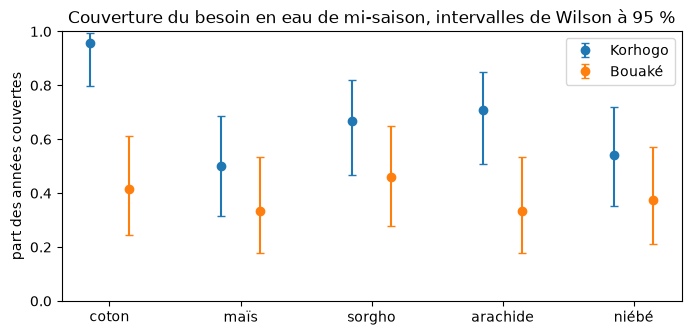

In [2]:
from moteur.criteres import couverture, debuts_par_annee, scores_rotations
fig, ax = plt.subplots(figsize=(8, 3.5))
cultures = list(config["cultures"])
for k, (lieu, s) in enumerate(series.items()):
    debuts = debuts_par_annee(s, config)
    for i, c in enumerate(cultures):
        r = couverture(s, config["cultures"][c], debuts)
        x = i + (k - 0.5) * 0.3
        ax.errorbar(x, r["part"], yerr=[[r["part"] - r["bas"]], [r["haut"] - r["part"]]], fmt="o", capsize=3,
                    color=f"C{k}", label=noms[lieu] if i == 0 else None)
        print(f"{noms[lieu]:8} {config['cultures'][c]['nom']:9} {r['couvertes']:2} années sur {r['annees']}")
ax.set_xticks(range(len(cultures)), [config["cultures"][c]["nom"] for c in cultures])
ax.set_ylabel("part des années couvertes"); ax.set_ylim(0, 1)
ax.set_title("Couverture du besoin en eau de mi-saison, intervalles de Wilson à 95 %"); ax.legend(); plt.show()

**Constat**

À Korhogo, le coton est presque toujours couvert, le maïs une année sur deux. À Bouaké, toutes les cultures sont couvertes moins d'une année sur deux.

**Analyse**

Les intervalles sont larges, avec 24 années seulement. Les écarts entre cultures d'un même lieu ne sont souvent pas distinguables.

In [3]:
from moteur.criteres import classer
for lieu, s in series.items():
    scores = scores_rotations(s, config, debuts_par_annee(s, config))
    print(noms[lieu])
    for r, v in scores.items():
        print(f"  {r:22} eau {v['eau']:.3f} sol {v['sol']:.3f} débouché {v['debouche']:.3f}")
    for cle, p in config["priorites"].items():
        print(f"  priorité {cle:9}", [(r, rang) for r, _, rang in classer(scores, p["poids"])])

Korhogo
  coton_mais             eau 0.729 sol 0.000 débouché 0.500
  coton_mais_arachide    eau 0.722 sol 0.333 débouché 0.333
  coton_sorgho_niebe     eau 0.722 sol 0.333 débouché 0.333
  priorité eau       [('coton_mais_arachide', 1), ('coton_sorgho_niebe', 1), ('coton_mais', 3)]
  priorité sol       [('coton_mais_arachide', 1), ('coton_sorgho_niebe', 1), ('coton_mais', 3)]
  priorité debouche  [('coton_mais', 1), ('coton_mais_arachide', 2), ('coton_sorgho_niebe', 2)]
Bouaké
  coton_mais             eau 0.375 sol 0.000 débouché 0.500
  coton_mais_arachide    eau 0.361 sol 0.333 débouché 0.333
  coton_sorgho_niebe     eau 0.417 sol 0.333 débouché 0.333
  priorité eau       [('coton_sorgho_niebe', 1), ('coton_mais_arachide', 2), ('coton_mais', 3)]
  priorité sol       [('coton_sorgho_niebe', 1), ('coton_mais_arachide', 2), ('coton_mais', 3)]
  priorité debouche  [('coton_mais', 1), ('coton_sorgho_niebe', 2), ('coton_mais_arachide', 3)]


**Constat**

À Korhogo, les scores eau des trois rotations sont presque identiques, et le classement dépend surtout des critères sol et débouché. À Bouaké, la rotation avec sorgho et niébé obtient le meilleur score eau.

**Analyse**

Les critères sol et débouché reposent sur des hypothèses déclarées, que l'application affiche comme telles.